# Descriptive Context Analysis

Analyze the dataframe with the paragraphs from the legal court data. The options to check:
- Paragraph-to-Paragraph within-documents
- Paragraph-to-Paragraph cross-documents
- Compute normalized centroid - semantic topology of paragraph classes
- Inter-class cohesion
- Inter-class separation
- K-nearest paragraphs
- Silhouette score

In [1]:
import numpy as np
import pandas as pd
import functional as pyf
import torch

In [ ]:
from google.cloud import storage, bigquery

In [ ]:
from datasets import Dataset

In [2]:
DATASET_PATH = "legal_paragraphs_dataset_v2.parquet"
ENCODER_PATH = "bge_model/bge-small-uk-law-v1_1/final/encoder"
TOKENIZER_PATH = "bge_model/bge-small-uk-law-v1_1/final/tokenizer"

In [ ]:
BUCKET_NAME = "court_data_2024_structured"
BUCKET_FILE_PATH = "document_text_parsing/info_version_9/2/{doc_id}/classification.parquet"

In [3]:
paragraph_dataset_mini = [
    "116062204", "116075685", "116080900", "116084352", "116084886", "116099338", "116102314", "116105977", "116106432", "116109598", "116110555", "116116081", "116118921", "116120654", "116121714", "116125191", "116126076", "116127831", "116141779", "116142769", "116149190", "116150283", "116167789", "116168634", "116170057", "116170822", "116192026", "116194637", "116196887", "116197578", "116199866", "116204676", "116213690", "116214232", "116220471", "116221948", "116226431", "116229939", "116232414", "116233794", "116245112", "116246991", "116248468", "116252607", "116253514", "116256069", "116257159", "116259036", "116260246", "116261015", "116261263", "116270112", "116277632", "116278949", "116283678", "116285648", "116289180", "116308208", "116310154", "116320626", "116321603", "116336690", "116339406", "116344031", "116350541", "116350825", "116358099", "116359089", "116376162", "116377931", "116385451", "116398308", "116410200", "116410462", "116414218", "116432495", "116434259", "116442566", "116462199", "116588653", "116681882", "116764649", "116780853", "116790074", "116794466", "116972204", "117069850", "117125134", "117130242", "117230819", "117251852", "117420480", "117440182", "117456818", "117460145", "117464049", "117489745", "117516936", "117556435"
]

### Downloading document paragraphs from the Cloud Storage

In [4]:
from pathlib import Path

In [ ]:
# Cloud clients are created only when a local document artifact is missing.
# This keeps Run All reproducible when the cached 99-document sample is present.

In [5]:
def locate_local_artifact_dir() -> Path:
    relative = Path("paragraph_analysis") / "doc_artifacts"
    candidates = []
    for root in (Path.cwd(), *Path.cwd().parents):
        candidates.extend([
            root / "doc_artifacts",
            root / relative,
            root / "src" / "legal_data_doc_parts" / relative,
        ])
    for candidate in candidates:
        if candidate.is_dir():
            return candidate.resolve()
    return (Path.cwd() / "doc_artifacts").resolve()


def download_necessary_docs(doc_list: list[str]) -> Path:
    local_doc_folder = locate_local_artifact_dir()
    local_doc_folder.mkdir(parents=True, exist_ok=True)
    missing_doc_ids = [
        doc_id for doc_id in doc_list
        if not (local_doc_folder / f"{doc_id}.parquet").is_file()
    ]
    if not missing_doc_ids:
        print(f"Using {len(doc_list)} cached document artifacts from {local_doc_folder}")
        return local_doc_folder

    data_bucket = storage.Client().bucket(BUCKET_NAME)
    for doc_id in missing_doc_ids:
        blob_path = BUCKET_FILE_PATH.format(doc_id=doc_id)
        data_bucket.blob(blob_path).download_to_filename(
            local_doc_folder / f"{doc_id}.parquet"
        )
    print(f"Downloaded {len(missing_doc_ids)} missing document artifacts")
    return local_doc_folder

In [6]:
DOC_ARTIFACT_DIR = download_necessary_docs(paragraph_dataset_mini)

Using 99 cached document artifacts from /home/vegura/Projects/study/legal-data-doc-parts/src/legal_data_doc_parts/paragraph_analysis/doc_artifacts


### Loading model for further usage

In [9]:
from sentence_transformers import models, SentenceTransformer

/tmp/ipykernel_381483/2111836941.py:1: DeprecationWarning: Importing from 'sentence_transformers.models' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.modules' instead.
  from sentence_transformers import models, SentenceTransformer


Fixing encoder model path

In [10]:
search_roots = (Path.cwd(), *Path.cwd().parents)
model_base = next(
    (
        base
        for root in search_roots
        for base in (root, root / "src" / "legal_data_doc_parts")
        if (base / ENCODER_PATH).is_dir() and (base / TOKENIZER_PATH).is_dir()
    ),
    None,
)
if model_base is None:
    raise FileNotFoundError(
        f"Could not locate {ENCODER_PATH!r} and {TOKENIZER_PATH!r} from {Path.cwd()}"
    )

In [11]:
transformer = models.Transformer(
    str(model_base / ENCODER_PATH),
    tokenizer_name_or_path=str(model_base / TOKENIZER_PATH),
)
pooling = models.Pooling(
    transformer.get_embedding_dimension(),
    pooling_mode="mean",
)
legal_encoder = SentenceTransformer(modules=[transformer, pooling])

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: /home/vegura/Projects/study/legal-data-doc-parts/src/legal_data_doc_parts/bge_model/bge-small-uk-law-v1_1/final/encoder
Key                 | Status  | 
--------------------+---------+-
pooler.dense.bias   | MISSING | 
pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
The `tokenizer_name_or_path` argument is deprecated and will be removed in a future version. Please use the same path for the model and processor.


Trying to compose all documents

In [7]:
def compose_full_dataframe(doc_ids: list[str]) -> pd.DataFrame:
    frames = [
        pd.read_parquet(DOC_ARTIFACT_DIR / f"{doc_id}.parquet")
        for doc_id in doc_ids
    ]
    return pd.concat(frames, ignore_index=True)

In [22]:
full_legal_doc_df = compose_full_dataframe(paragraph_dataset_mini)
full_legal_reasoning_doc_df = (
    full_legal_doc_df.loc[full_legal_doc_df["section"] == "reasoning"]
    .copy()
    .reset_index(drop=True)
)

In [12]:
reasoning_text_list = full_legal_reasoning_doc_df["text"].to_list()
full_paragraph_embeddings = legal_encoder.encode(
    reasoning_text_list,
    batch_size=32,
    normalize_embeddings=True,
    show_progress_bar=True,
    convert_to_numpy=True
)

Batches:   0%|          | 0/80 [00:00<?, ?it/s]

### Measuring cosine similarity

In [13]:
from sklearn.metrics.pairwise import cosine_similarity
import torch.nn.functional as F
import torch

In [14]:
def process_distances(embeddings, global_batch_size, local_batch_size, device="cuda"):
    embeddings = np.asanyarray(embeddings, dtype=np.float32)
    n = embeddings.shape[0]
    distances = np.empty((n, n), dtype=np.float32)

    with torch.inference_mode():
        for global_start in range(0, n, global_batch_size):
            global_end = min(global_start + global_batch_size, n)
            global_embeddings = torch.as_tensor(
                embeddings[global_start:global_end],
                dtype=torch.float32,
                device=device
            )
            global_embeddings = F.normalize(global_embeddings, p=2, dim=1)

            for row_start in range(global_start, global_end, local_batch_size):
                row_end = min(row_start + local_batch_size, global_end)

                row_offset_start = row_start - global_start
                row_offset_end = row_end - global_start
                x = global_embeddings[row_offset_start: row_offset_end]

                for col_start in range(row_start, n, local_batch_size):
                    col_end = min(col_start + local_batch_size, n)

                    if global_start <= col_start and col_end <= global_end:
                        y = global_embeddings[col_start - global_start: col_end - global_start]
                    else:
                        y = torch.as_tensor(
                            embeddings[col_start: col_end],
                            dtype=torch.float32,
                            device=device,
                        )

                    similarity = (x @ y.T).cpu().numpy()
                    distances[row_start:row_end, col_start:col_end] = similarity
                    distances[col_start:col_end, row_start:row_end] = similarity.T

                    del y, similarity

            del global_embeddings

        np.fill_diagonal(distances, 1.0)
        return distances

In [23]:
distance_device = "cuda" if torch.cuda.is_available() else "cpu"
D = 1 - process_distances(
    full_paragraph_embeddings, 32, 8, device=distance_device
)
np.fill_diagonal(D, np.float32(0.0))
D[D < 0] = 0

In [ ]:
D.shape

## Plotting distance matrix as heatmap

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
sns.heatmap(D)

In [ ]:
from sklearn.neighbors import NearestNeighbors

In [ ]:
def optimal_epsilon_plot(dist_m, min_samples):
    plt.figure(figsize=(10, 10))

    nn = NearestNeighbors(n_neighbors=min_samples, metric="precomputed")
    nn.fit(dist_m)
    distances, indicies = nn.kneighbors(dist_m)
    k_distances = distances[:, -1]
    k_distances = np.sort(k_distances)
    plt.plot(k_distances)

    plt.xlabel("Points sorted by distance")
    plt.ylabel(f"{min_samples}-NN distance")
    plt.title("k-distance Graph for DBScan")
    plt.grid(True)
    plt.show()

In [ ]:
optimal_epsilon_plot(D, 3)

## Clustering context-similar paragraphs

HDBSCAN retains the original density-clustering idea while avoiding a single manually selected epsilon. The parameters below were selected in the separate comparison notebook with three safeguards: at least 25% coverage, no cluster larger than 15% of assigned paragraphs, and the best coverage-adjusted silhouette among eligible candidates.

In [16]:
from sklearn.cluster import DBSCAN, HDBSCAN
from sklearn.metrics import silhouette_score

In [ ]:
type(D)

In [24]:
legal_par_cluster = HDBSCAN(
    min_cluster_size=5,
    min_samples=3,
    metric="precomputed",
    copy=True,
).fit_predict(D.astype(np.float64))

assigned_mask = legal_par_cluster >= 0
assigned_labels = legal_par_cluster[assigned_mask]
cluster_quality_summary = pd.Series({
    "paragraphs": len(legal_par_cluster),
    "assigned_paragraphs": int(assigned_mask.sum()),
    "coverage": float(assigned_mask.mean()),
    "clusters": int(np.unique(assigned_labels).size),
    "largest_cluster": int(pd.Series(assigned_labels).value_counts().max()),
    "silhouette_assigned": float(silhouette_score(
        D[np.ix_(assigned_mask, assigned_mask)],
        assigned_labels,
        metric="precomputed",
    )),
}, name="value")
cluster_quality_summary.to_frame()

,value
paragraphs,2534.000000
assigned_paragraphs,1119.000000
coverage,0.441594
clusters,77.000000
largest_cluster,96.000000
silhouette_assigned,0.497479


In [ ]:
pd.Series(legal_par_cluster[legal_par_cluster >= 0]).value_counts().sort_index().describe()

Fetching similar paragraphs

In [25]:
full_legal_reasoning_doc_df["cluster"] = legal_par_cluster
clustered_paragraphs = (
    full_legal_reasoning_doc_df
    .loc[full_legal_reasoning_doc_df["cluster"] != -1]
    .sort_values("cluster")
)

In [34]:
full_legal_reasoning_doc_df.sort_values(by="cluster", inplace=True)
full_legal_reasoning_doc_df[full_legal_reasoning_doc_df["cluster"] != -1]

,document_id,paragraph_index,paragraph_order,numbered_text,text,section,cluster
1996,116588653,17,17,[paragraph_id=17] В С Т А Н О В И В:,В С Т А Н О В И В:,reasoning,0
1763,116376162,13,13,[paragraph_id=13] В С Т А Н О В И В :,В С Т А Н О В И В :,reasoning,0
1249,116259036,11,11,[paragraph_id=11] В С Т А Н О В И В:,В С Т А Н О В И В:,reasoning,0
521,116127831,20,20,[paragraph_id=20] в с т а н о в и в :,в с т а н о в и в :,reasoning,0
1277,116260246,13,13,[paragraph_id=13] В С Т А Н О В И В:,В С Т А Н О В И В:,reasoning,0
...,...,...,...,...,...,...,...
294,116106432,27,27,[paragraph_id=27] При призначенні покарання об...,При призначенні покарання обвинуваченому ОСОБА...,reasoning,76
765,116194637,22,22,[paragraph_id=22] При призначенні покарання об...,"При призначенні покарання обвинуваченому, відп...",reasoning,76
1159,116252607,88,88,[paragraph_id=88] Призначаючи покарання обвину...,"Призначаючи покарання обвинуваченим суд, згідн...",reasoning,76
1916,116414218,27,27,[paragraph_id=27] При призначенні покарання об...,При призначенні покарання обвинуваченій ОСОБА_...,reasoning,76


## Intra-Class Cohesion

In [26]:
clustered_indices = {
    cluster_id: group.index.to_numpy()
    for cluster_id, group in full_legal_reasoning_doc_df.loc[
        full_legal_reasoning_doc_df["cluster"] >= 0
    ].groupby("cluster")
}

In [27]:
def cohesion_within_clusters(cluster_map: dict[int, np.ndarray]) -> pd.DataFrame:
    rows = []
    for cluster_id, indices in cluster_map.items():
        cluster_embeddings = full_paragraph_embeddings[indices]
        similarities = cluster_embeddings @ cluster_embeddings.T
        upper = similarities[np.triu_indices(len(indices), k=1)]
        rows.append({
            "cluster": int(cluster_id),
            "size": len(indices),
            "mean_pairwise_cosine": float(upper.mean()),
            "minimum_pairwise_cosine": float(upper.min()),
        })
    return pd.DataFrame(rows).sort_values("cluster").reset_index(drop=True)


cluster_cohesion = cohesion_within_clusters(clustered_indices)
cluster_cohesion.describe().round(4)

,cluster,size,mean_pairwise_cosine,minimum_pairwise_cosine
count,77.0000,77.0000,77.0000,77.0000
mean,38.0000,14.5325,0.9601,0.9183
std,22.3719,15.0347,0.0222,0.0513
min,0.0000,5.0000,0.8987,0.7299
25%,19.0000,6.0000,0.9496,0.8932
50%,38.0000,9.0000,0.9615,0.9340
75%,57.0000,14.0000,0.9768,0.9524
max,76.0000,96.0000,0.9996,0.9989


## Global graph from the current paragraph alignment

This section squashes the **existing HDBSCAN alignment** into a directed global graph for all reasoning paragraphs in the selected document sample.

- Each nonnegative cluster becomes one node `C<cluster>`. Each noise paragraph (`cluster == -1`) keeps its own node `P<original row>`; noise is never merged into one artificial cluster.
- Within each document, paragraphs are ordered by `paragraph_order`. An edge means **next retained reasoning paragraph**, possibly across a gap in the original document. These are sequence links, not inferred legal support/attack relations.
- Parallel sequence links are combined by summing their occurrence counts. Document IDs, original endpoint rows, full paragraph metadata/text, and links that become self-loops are retained.
- Node centroids and representative paragraphs summarize the members; the original text and embedding indices remain available in `global_members`, `paragraph_graph`, and `full_paragraph_embeddings`.
- The full figure includes every global node and edge. The aligned-node figure is an explicitly filtered detail view; no paths through omitted noise nodes are invented.

Scope: the reasoning section already analyzed above, across the selected documents; this does not add unaligned sections or documents outside that sample.

In [28]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize
from matplotlib.lines import Line2D
from IPython.display import Markdown, display

GLOBAL_LAYOUT_SEED = 42
GLOBAL_FIGURE_DIR = DOC_ARTIFACT_DIR.parent / "global_graph_artifacts"
GLOBAL_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def save_global_figure(figure, name):
    for extension in ("png", "svg"):
        figure.savefig(
            GLOBAL_FIGURE_DIR / f"{name}.{extension}",
            dpi=180, bbox_inches="tight", facecolor="white",
        )
    plt.show()


In [29]:
# Restore embedding order: an earlier display cell sorts the dataframe by cluster.
global_members = (
    full_legal_reasoning_doc_df.sort_index()
    .rename_axis("paragraph_row").reset_index().copy()
)
assert np.array_equal(global_members["paragraph_row"], np.arange(len(legal_par_cluster)))
assert np.array_equal(global_members["cluster"], legal_par_cluster)
assert len(global_members) == len(full_paragraph_embeddings)
assert not global_members.duplicated(["document_id", "paragraph_order"]).any()
assert global_members[["document_id", "paragraph_order", "text", "cluster"]].notna().all().all()
assert np.isfinite(full_paragraph_embeddings).all()

global_members["global_node_id"] = [
    f"C{int(cluster)}" if cluster >= 0 else f"P{int(row)}"
    for row, cluster in zip(global_members["paragraph_row"], global_members["cluster"])
]

# Keep the original attributed paragraph graph as well as its squashed version.
paragraph_graph = nx.DiGraph(scope="reasoning", relation="next_reasoning_paragraph")
for member in global_members.to_dict("records"):
    paragraph_graph.add_node(member["paragraph_row"], **member)

global_graph = nx.DiGraph(
    scope="reasoning",
    alignment="HDBSCAN(min_cluster_size=5, min_samples=3, metric=precomputed)",
    relation="next_reasoning_paragraph",
    edge_weight="number of original sequence transitions",
)
node_records = []
for node_id, members in global_members.groupby("global_node_id", sort=False):
    rows = members["paragraph_row"].to_numpy(dtype=int)
    member_embeddings = full_paragraph_embeddings[rows]
    centroid = member_embeddings.mean(axis=0)
    centroid = centroid / max(float(np.linalg.norm(centroid)), 1e-12)
    representative_row = int(rows[np.argmax(member_embeddings @ centroid)])
    representative = members.loc[members["paragraph_row"] == representative_row].iloc[0]
    document_ids = sorted(members["document_id"].astype(str).unique().tolist())
    attributes = {
        "cluster": int(members["cluster"].iloc[0]),
        "kind": "aligned" if members["cluster"].iloc[0] >= 0 else "unclustered",
        "paragraph_count": len(members),
        "document_count": len(document_ids),
        "document_ids": document_ids,
        "member_rows": rows.tolist(),
        "members": members.to_dict("records"),
        "centroid_embedding": centroid,
        "representative_row": representative_row,
        "representative_text": representative["text"],
    }
    global_graph.add_node(node_id, **attributes)
    node_records.append({
        "node_id": node_id,
        **{key: attributes[key] for key in (
            "kind", "cluster", "paragraph_count", "document_count",
            "representative_row", "representative_text",
        )},
    })
global_nodes = pd.DataFrame(node_records).set_index("node_id")

transition_records = []
for document_id, members in global_members.groupby("document_id", sort=True):
    ordered = members.sort_values(["paragraph_order", "paragraph_row"])
    records = ordered.to_dict("records")
    for source, target in zip(records, records[1:]):
        transition_records.append({
            "document_id": str(document_id),
            "source_row": int(source["paragraph_row"]),
            "target_row": int(target["paragraph_row"]),
            "source_order": int(source["paragraph_order"]),
            "target_order": int(target["paragraph_order"]),
            "source": source["global_node_id"],
            "target": target["global_node_id"],
        })
        paragraph_graph.add_edge(
            source["paragraph_row"], target["paragraph_row"],
            document_id=str(document_id), relation="next_reasoning_paragraph",
        )
global_transitions = pd.DataFrame(transition_records, columns=[
    "document_id", "source_row", "target_row", "source_order",
    "target_order", "source", "target",
])

edge_records = []
for (source, target), transitions in global_transitions.groupby(["source", "target"], sort=True):
    document_ids = sorted(transitions["document_id"].unique().tolist())
    attributes = {
        "weight": len(transitions),
        "document_count": len(document_ids),
        "document_ids": document_ids,
        "relation": "next_reasoning_paragraph",
        "evidence": transitions.to_dict("records"),
    }
    global_graph.add_edge(source, target, **attributes)
    edge_records.append({
        "source": source, "target": target,
        "weight": len(transitions), "document_count": len(document_ids),
        "is_self_loop": source == target,
    })
global_edges = pd.DataFrame(edge_records, columns=[
    "source", "target", "weight", "document_count", "is_self_loop",
])
aligned_nodes = [node for node, data in global_graph.nodes(data=True) if data["kind"] == "aligned"]
noise_nodes = [node for node, data in global_graph.nodes(data=True) if data["kind"] == "unclustered"]
aligned_global_graph = global_graph.subgraph(aligned_nodes).copy()


In [30]:
# Conservation checks: squashing must account for every original record and edge.
expected_transitions = len(global_members) - global_members["document_id"].nunique()
member_lookup = global_members.set_index("paragraph_row")
retained_rows = [row for _, data in global_graph.nodes(data=True) for row in data["member_rows"]]
assert sorted(retained_rows) == list(range(len(global_members)))
assert len(noise_nodes) == int((legal_par_cluster == -1).sum())
assert len(aligned_nodes) == len(np.unique(legal_par_cluster[legal_par_cluster >= 0]))
assert len(global_transitions) == paragraph_graph.number_of_edges() == expected_transitions
assert int(global_edges["weight"].sum()) == expected_transitions
assert (global_transitions["source_order"] < global_transitions["target_order"]).all()
for source, target, data in global_graph.edges(data=True):
    assert data["weight"] == len(data["evidence"])
    assert data["document_count"] == len({item["document_id"] for item in data["evidence"]})
    for item in data["evidence"]:
        original_source = member_lookup.loc[item["source_row"]]
        original_target = member_lookup.loc[item["target_row"]]
        assert original_source["global_node_id"] == source
        assert original_target["global_node_id"] == target
        assert original_source["document_id"] == original_target["document_id"] == item["document_id"]
        assert paragraph_graph.has_edge(item["source_row"], item["target_row"])

source_columns = full_legal_reasoning_doc_df.columns
pd.testing.assert_frame_equal(
    member_lookup[source_columns].sort_index(),
    full_legal_reasoning_doc_df.sort_index(),
    check_names=False,
)
global_graph_summary = pd.Series({
    "Source documents": global_members["document_id"].nunique(),
    "Original reasoning paragraphs": len(global_members),
    "Paragraphs in aligned clusters": int((legal_par_cluster >= 0).sum()),
    "Merged cluster nodes": len(aligned_nodes),
    "Unclustered singleton nodes": len(noise_nodes),
    "Total global nodes": global_graph.number_of_nodes(),
    "Original sequence transitions": expected_transitions,
    "Distinct global directed edges (including loops)": global_graph.number_of_edges(),
    "Total preserved edge weight": int(global_edges["weight"].sum()),
    "Self-loop edges": nx.number_of_selfloops(global_graph),
    "Transitions inside merged nodes": int(global_edges.loc[global_edges["is_self_loop"], "weight"].sum()),
    "Weakly connected components": nx.number_weakly_connected_components(global_graph),
    "Isolated global nodes": nx.number_of_isolates(global_graph),
}, name="count").astype(int)
display(global_graph_summary.to_frame())
display(Markdown(
    f"**All conservation checks passed.** {len(global_members):,} paragraphs become "
    f"{global_graph.number_of_nodes():,} nodes "
    f"({1 - global_graph.number_of_nodes() / len(global_members):.1%} fewer nodes). "
    f"All {expected_transitions:,} original sequence transitions and all source metadata are retained."
))

# Compact readable examples; full texts are retained in global_nodes/global_members.
global_node_examples = (
    global_nodes.loc[aligned_nodes]
    .sort_values(["document_count", "paragraph_count"], ascending=False).head(12).copy()
)
global_node_examples["text_preview"] = global_node_examples["representative_text"].str.slice(0, 160)
display(global_node_examples[["paragraph_count", "document_count", "text_preview"]])


,count
Source documents,99
Original reasoning paragraphs,2534
Paragraphs in aligned clusters,1119
Merged cluster nodes,77
Unclustered singleton nodes,1415
Total global nodes,1492
Original sequence transitions,2435
Distinct global directed edges (including loops),2122
Total preserved edge weight,2435
Self-loop edges,24


**All conservation checks passed.** 2,534 paragraphs become 1,492 nodes (41.1% fewer nodes). All 2,435 original sequence transitions and all source metadata are retained.

,paragraph_count,document_count,text_preview
node_id,,,
C8,96,96,"На підставі викладеного, керуючись ст. ст. 368..."
C1,53,52,ВСТАНОВИВ:
C16,51,49,Питання щодо речових доказів суд вирішує у від...
C0,47,47,В С Т А Н О В И В:
C34,47,46,"Обставинами, які пом`якшують покарання ОСОБА_2..."
C75,41,38,"Призначаючи покарання ОСОБА_3 , суд враховує т..."
C65,50,30,"Обвинуваченим ОСОБА_3 подано заяву, яка склад..."
C61,28,26,"Крім визнання своєї вини обвинуваченим, його в..."
C36,26,26,"Обставин, що обтяжують покарання ОСОБА_4 відпо..."


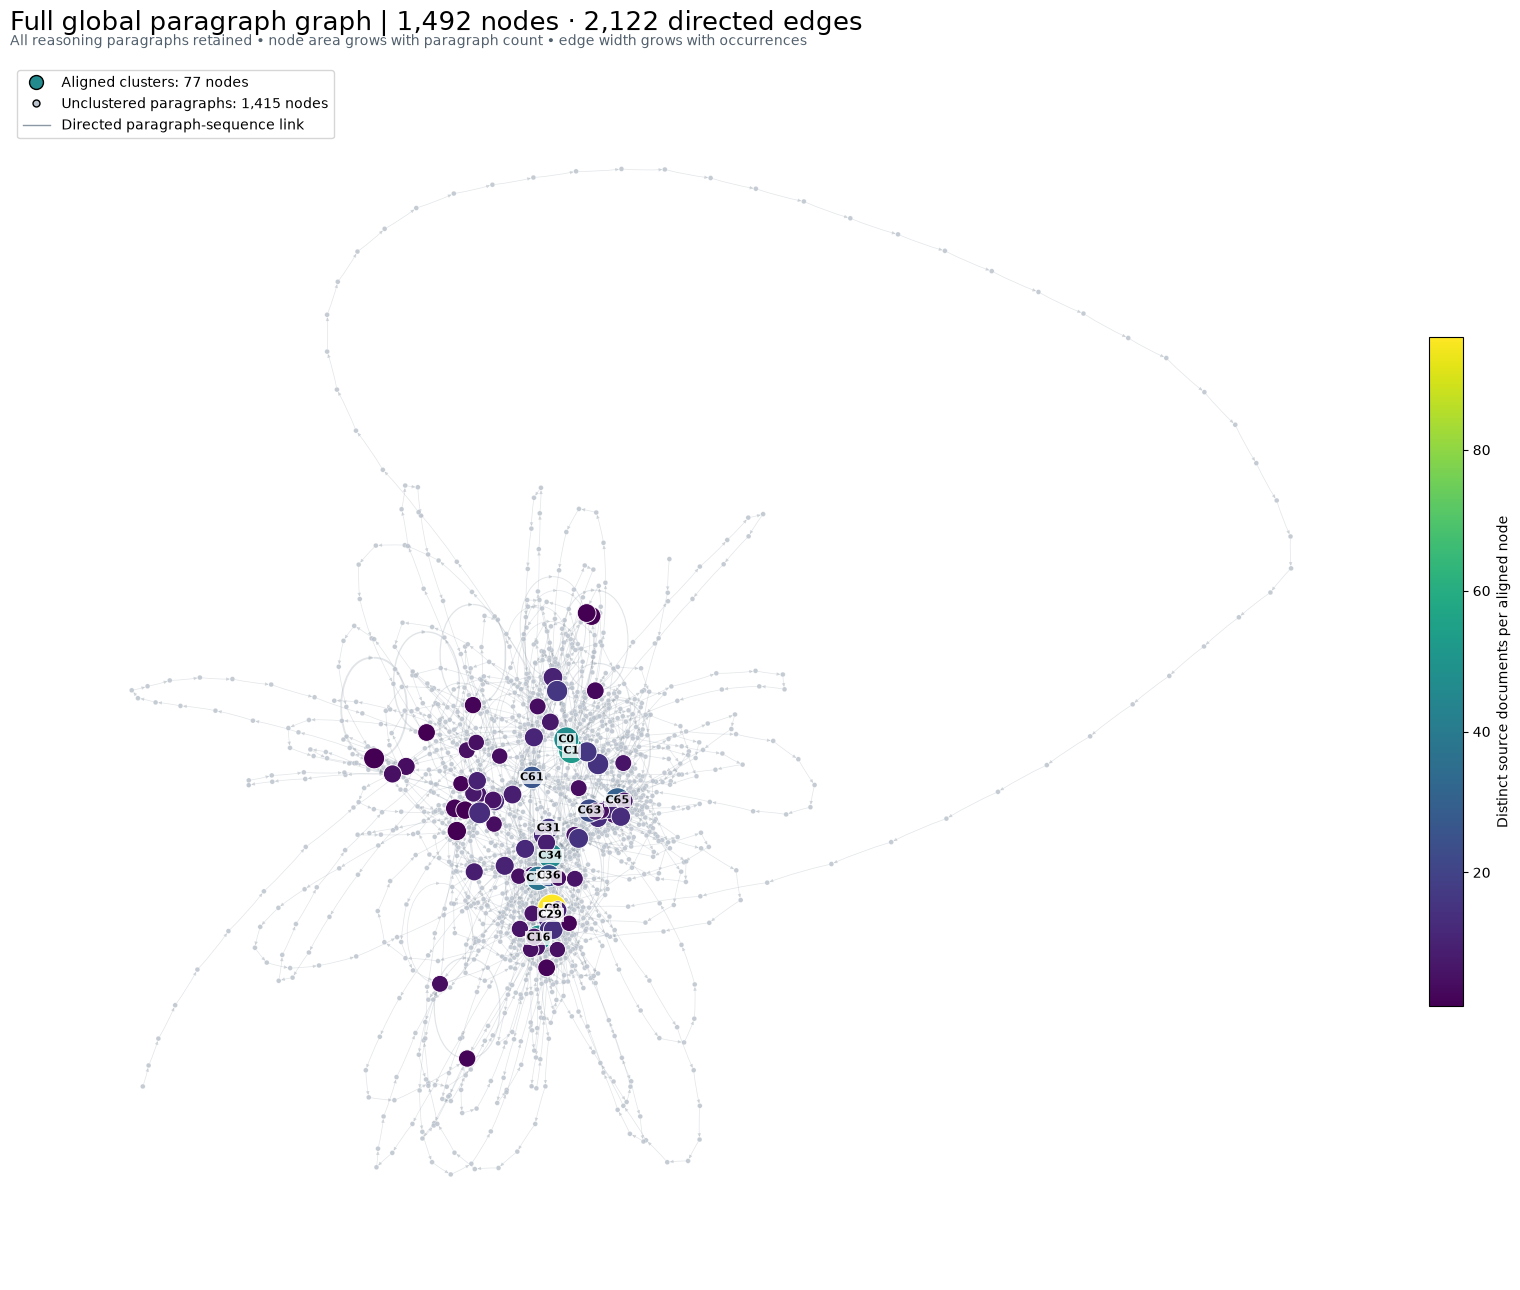

In [31]:
# Figure 1: every node and every edge, including unclustered paragraphs and loops.
layout_graph = nx.Graph()
layout_graph.add_nodes_from(global_graph)
for source, target, data in global_graph.edges(data=True):
    if source != target:
        previous = layout_graph.get_edge_data(source, target, {}).get("weight", 0)
        layout_graph.add_edge(source, target, weight=previous + data["weight"])
global_positions = nx.spring_layout(
    layout_graph, seed=GLOBAL_LAYOUT_SEED, weight="weight", iterations=160,
)
global_node_sizes = {
    node: 12 if data["kind"] == "unclustered" else 50 + 40 * np.sqrt(data["paragraph_count"])
    for node, data in global_graph.nodes(data=True)
}
document_norm = Normalize(
    vmin=1, vmax=max(2, int(global_nodes["document_count"].max()))
)
figure, ax = plt.subplots(figsize=(17, 13), facecolor="white")
nx.draw_networkx_edges(
    global_graph, global_positions, ax=ax,
    node_size=[global_node_sizes[node] for node in global_graph],
    width=[0.25 + 0.38 * np.log1p(data["weight"]) for _, _, data in global_graph.edges(data=True)],
    edge_color="#8c99a5", alpha=0.25, arrows=True, arrowsize=5,
    connectionstyle="arc3,rad=0.035",
)
nx.draw_networkx_nodes(
    global_graph, global_positions, nodelist=noise_nodes,
    node_size=[global_node_sizes[node] for node in noise_nodes],
    node_color="#bac2cc", edgecolors="white", linewidths=0.2, alpha=0.85, ax=ax,
)
if aligned_nodes:
    nx.draw_networkx_nodes(
        global_graph, global_positions, nodelist=aligned_nodes,
        node_size=[global_node_sizes[node] for node in aligned_nodes],
        node_color=[global_graph.nodes[node]["document_count"] for node in aligned_nodes],
        cmap="viridis", vmin=document_norm.vmin, vmax=document_norm.vmax,
        edgecolors="white", linewidths=0.65, ax=ax,
    )
    label_nodes = global_nodes.loc[aligned_nodes].nlargest(12, "document_count").index
    nx.draw_networkx_labels(
        global_graph, global_positions, labels={node: node for node in label_nodes},
        font_size=8, font_weight="bold", ax=ax,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8, "pad": 1},
    )
    figure.colorbar(
        plt.cm.ScalarMappable(norm=document_norm, cmap="viridis"),
        ax=ax, shrink=0.55, pad=0.01, label="Distinct source documents per aligned node",
    )
ax.legend(handles=[
    Line2D([], [], marker="o", color="none", markerfacecolor="#238a8d", markersize=10,
           label=f"Aligned clusters: {len(aligned_nodes):,} nodes"),
    Line2D([], [], marker="o", color="none", markerfacecolor="#bac2cc", markersize=5,
           label=f"Unclustered paragraphs: {len(noise_nodes):,} nodes"),
    Line2D([], [], color="#8c99a5", linewidth=1, label="Directed paragraph-sequence link"),
], loc="upper left", frameon=True)
ax.set_title(
    f"Full global paragraph graph | {global_graph.number_of_nodes():,} nodes · "
    f"{global_graph.number_of_edges():,} directed edges",
    fontsize=19, loc="left", pad=24,
)
ax.text(
    0, 1.015,
    "All reasoning paragraphs retained • node area grows with paragraph count • edge width grows with occurrences",
    transform=ax.transAxes, fontsize=10, color="#52606d",
)
ax.set_axis_off()
figure.tight_layout()
save_global_figure(figure, "01_full_global_graph")


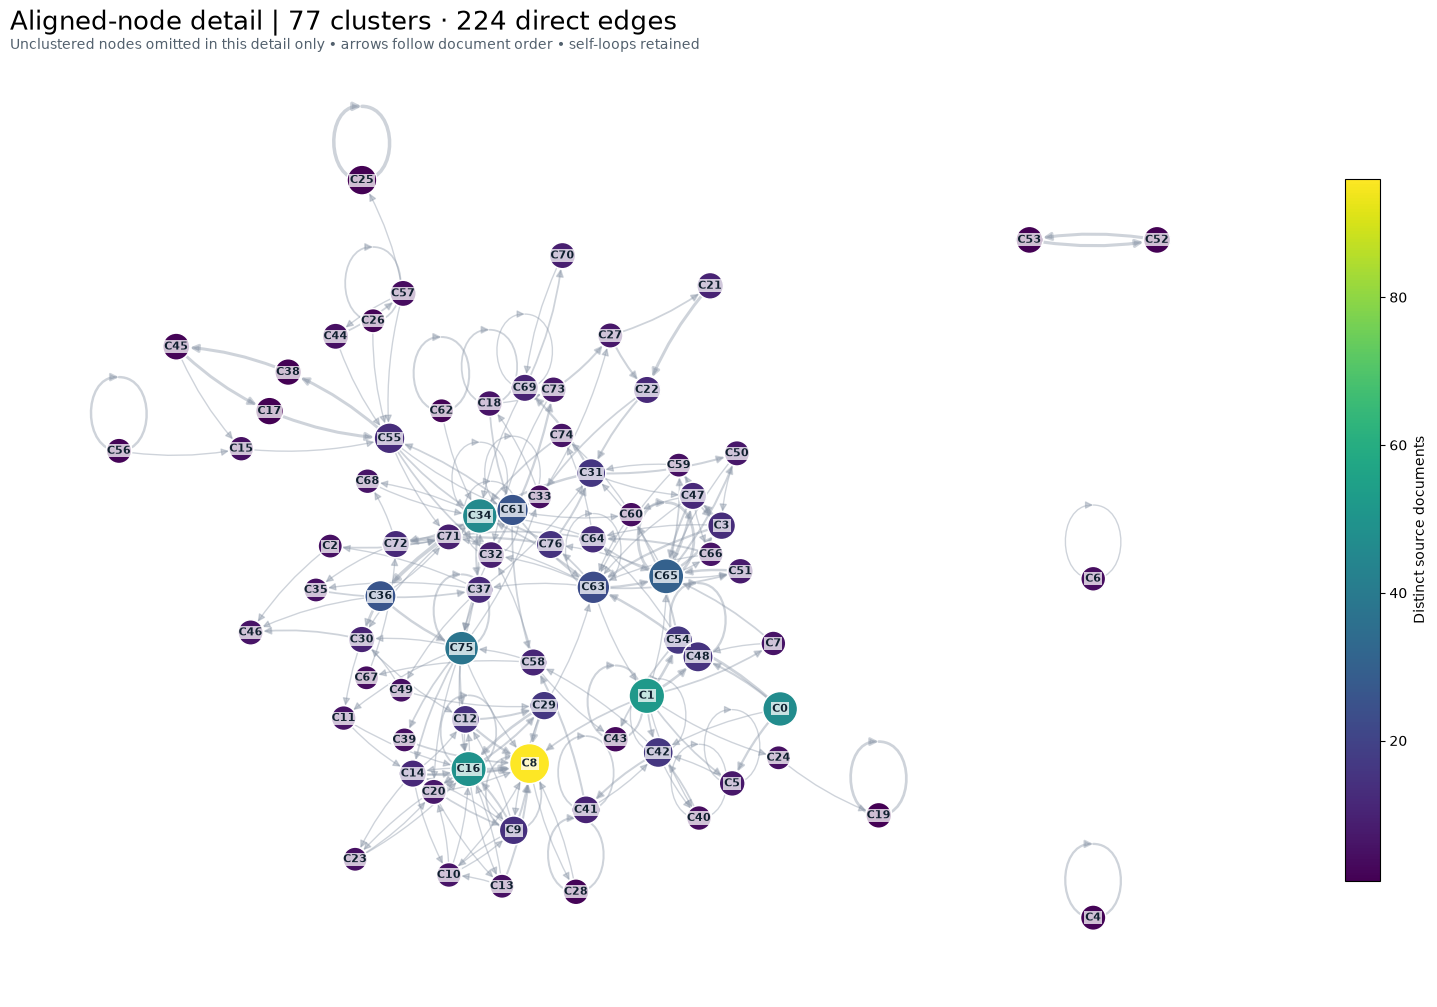

In [35]:
# Figure 2: all aligned nodes, with only their original direct sequence links.
# Pack disconnected components separately so small components do not compress the main graph.
aligned_components = sorted(
    nx.weakly_connected_components(aligned_global_graph), key=len, reverse=True,
)
aligned_positions = {}
for component_index, component in enumerate(aligned_components):
    component_graph = aligned_global_graph.subgraph(
        [node for node in aligned_global_graph if node in component]
    ).to_undirected()
    component_positions = nx.kamada_kawai_layout(component_graph, weight=None)
    if component_index == 0:
        aligned_positions.update(component_positions)
    else:
        center_y = 0.85 - 1.7 * (component_index - 1) / max(1, len(aligned_components) - 2)
        for node, point in component_positions.items():
            aligned_positions[node] = np.asarray([1.45, center_y]) + 0.16 * point
figure, ax = plt.subplots(figsize=(16, 12), facecolor="white")
if aligned_nodes:
    aligned_sizes = [
        150 + 70 * np.sqrt(aligned_global_graph.nodes[node]["paragraph_count"])
        for node in aligned_global_graph
    ]
    nx.draw_networkx_edges(
        aligned_global_graph, aligned_positions, ax=ax, node_size=aligned_sizes,
        width=[0.5 + 0.7 * np.log1p(data["weight"])
               for _, _, data in aligned_global_graph.edges(data=True)],
        edge_color="#8b97a8", alpha=0.42, arrows=True, arrowsize=11,
        connectionstyle="arc3,rad=0.09",
    )
    nx.draw_networkx_nodes(
        aligned_global_graph, aligned_positions, ax=ax, node_size=aligned_sizes,
        node_color=[aligned_global_graph.nodes[node]["document_count"] for node in aligned_global_graph],
        cmap="viridis", vmin=document_norm.vmin, vmax=document_norm.vmax,
        edgecolors="#ffffff", linewidths=1.1,
    )
    nx.draw_networkx_labels(
        aligned_global_graph, aligned_positions, ax=ax, font_size=8,
        font_color="#10202f", font_weight="bold",
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.75, "pad": 0.7},
    )
    figure.colorbar(
        plt.cm.ScalarMappable(norm=document_norm, cmap="viridis"),
        ax=ax, shrink=0.6, label="Distinct source documents",
    )
ax.set_title(
    f"Aligned-node detail | {len(aligned_nodes):,} clusters · "
    f"{aligned_global_graph.number_of_edges():,} direct edges",
    fontsize=19, loc="left", pad=24,
)
ax.text(
    0, 1.015,
    "Unclustered nodes omitted in this detail only • arrows follow document order • self-loops retained",
    transform=ax.transAxes, fontsize=10, color="#52606d",
)
ax.set_aspect("equal")
ax.set_axis_off()
figure.tight_layout()
save_global_figure(figure, "02_aligned_global_graph")


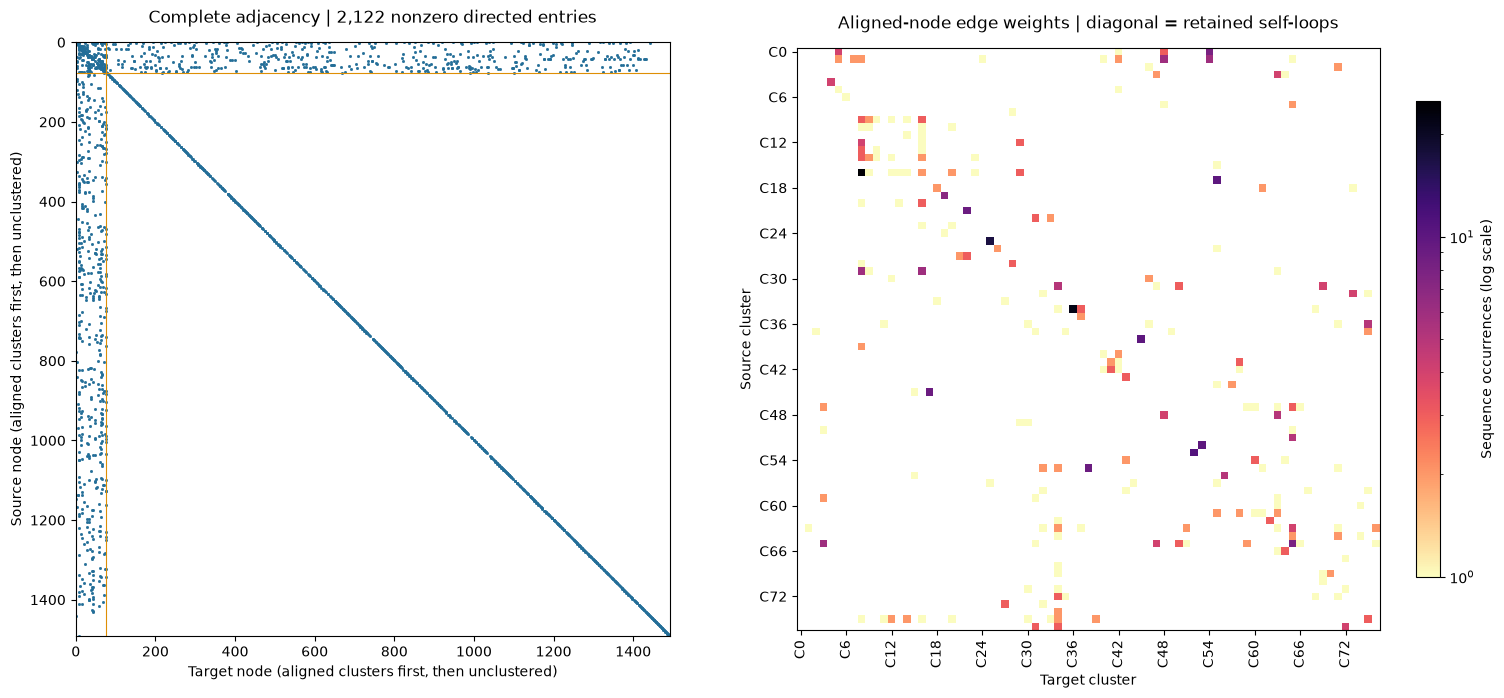

Figures are embedded above and saved as PNG/SVG in `/home/vegura/Projects/study/legal-data-doc-parts/src/legal_data_doc_parts/paragraph_analysis/global_graph_artifacts`. Inspect `global_graph` for the complete graph, `global_members` for original paragraphs, `global_transitions` for edge provenance, and `global_nodes` / `global_edges` for summaries.

In [33]:
# Figure 3: adjacency views make every edge visible without layout overlap.
matrix_nodes = sorted(aligned_nodes, key=lambda node: global_graph.nodes[node]["cluster"]) + noise_nodes
global_adjacency = nx.to_scipy_sparse_array(
    global_graph, nodelist=matrix_nodes, weight="weight", dtype=np.int64, format="csr",
)
assert int(global_adjacency.sum()) == len(global_transitions)
figure, axes = plt.subplots(1, 2, figsize=(16, 7), facecolor="white")
axes[0].spy(global_adjacency, markersize=1.0, color="#236e98")
boundary = len(aligned_nodes) - 0.5
axes[0].axhline(boundary, color="#de8f05", linewidth=0.8)
axes[0].axvline(boundary, color="#de8f05", linewidth=0.8)
axes[0].set_title(
    f"Complete adjacency | {global_adjacency.nnz:,} nonzero directed entries",
    fontsize=12, pad=14,
)
axes[0].set_xlabel("Target node (aligned clusters first, then unclustered)")
axes[0].set_ylabel("Source node (aligned clusters first, then unclustered)")
axes[0].xaxis.tick_bottom()
if aligned_nodes:
    aligned_matrix_nodes = matrix_nodes[:len(aligned_nodes)]
    aligned_adjacency = nx.to_numpy_array(
        aligned_global_graph, nodelist=aligned_matrix_nodes, weight="weight",
    )
    masked_adjacency = np.ma.masked_equal(aligned_adjacency, 0)
    heatmap = axes[1].imshow(
        masked_adjacency, cmap="magma_r",
        norm=LogNorm(vmin=1, vmax=max(2, float(aligned_adjacency.max()))),
        interpolation="nearest",
    )
    tick_indices = np.arange(0, len(aligned_nodes), max(1, len(aligned_nodes) // 12))
    axes[1].set_xticks(tick_indices, [aligned_matrix_nodes[index] for index in tick_indices], rotation=90)
    axes[1].set_yticks(tick_indices, [aligned_matrix_nodes[index] for index in tick_indices])
    figure.colorbar(heatmap, ax=axes[1], shrink=0.8, label="Sequence occurrences (log scale)")
axes[1].set_title("Aligned-node edge weights | diagonal = retained self-loops", fontsize=12, pad=14)
axes[1].set_xlabel("Target cluster")
axes[1].set_ylabel("Source cluster")
figure.tight_layout()
save_global_figure(figure, "03_global_graph_adjacency")
display(Markdown(
    "Figures are embedded above and saved as PNG/SVG in "
    f"`{GLOBAL_FIGURE_DIR}`. "
    "Inspect `global_graph` for the complete graph, `global_members` for original paragraphs, "
    "`global_transitions` for edge provenance, and `global_nodes` / `global_edges` for summaries."
))
